we fitted u+1-13C (combined) and looked at 20% best fitting samples. 
THen looked at statisctically different reactions : has the fitting impacted the sampled distributions .
NOw we look WT vs TM6, with reducing dimensions of the space and looking if there might be a multimode distribution

In [100]:
import sys
sys.path.append('/home/nathan/thermo_flux')

import pandas as pd
import os
# Add the parent directory to sys.path
sys.path.append(os.path.abspath('../3_src/'))
# Now import Model from freeflux

import numpy as np

import seaborn as sns
import analysis.io_func as io_func
import analysis.an_func as an_func
import matplotlib.pyplot as plt
from analysis import config_13c as config
import umap

In [101]:
import thermo_flux

In [102]:
# Import general configs:
palette ,cfg =io_func.import_plotconfigs()

In [103]:
condition = cond = 'WT'

In [104]:
model=config.model
net_flux_df=config.full_flux_df(condition)
# net_flux_df=pd.read_csv(config.flux_file(condition),index_col=0)
# net_flux_df.columns=[int(c) for c in range(len(net_flux_df.columns))]
obj_vals=config.obj_vals(condition)
# obj_vals=obj_vals[obj_vals<np.percentile(obj_vals,85)]
# accepted_samples=obj_vals[obj_vals<=config.find_plateau(obj_vals)].index
nperc=10
accepted_samples=obj_vals[obj_vals<=np.percentile(obj_vals,nperc)].index
# accepted_samples=accepted_samples[:28] ### previously the cutoff justifcation was based on umap reduciton : we take the N first samples that are together in one cluster.
## was doing it manually I thnk ? ## todo when we have 1000 samples for both condition
# len(accepted_samples)


In [105]:
net_flux_df_umap_WT=net_flux_df.loc[:,obj_vals.index]


In [106]:
condition = cond = 'WT'
net_flux_df=config.full_flux_df(condition)
obj_vals=config.obj_vals(condition)
# obj_vals=obj_vals[obj_vals<5e4]

net_flux_df_umap_TM6=net_flux_df.loc[:,obj_vals.index]
nperc=5
accepted_samples=obj_vals[obj_vals<=np.percentile(obj_vals,nperc)].index

In [107]:
obj_vals.describe()

count     996.000000
mean      334.991447
std       109.033140
min       291.760810
25%       302.526036
50%       309.297467
75%       323.811474
max      1707.006827
dtype: float64

## load optimal solutions from remote fitting and look at obj value

## dimensionnality reduction or clustering : compare initial points and accepted points


In [108]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# --- combine both conditions along samples (columns) ---
combined_df =net_flux_df_umap_WT if condition == 'WT' else net_flux_df_umap_TM6 #pd.concat([#net_flux_df_umap_WT, net_flux_df_umap_TM6], axis=1)  # fluxes x (samples_WT + samples_TM6)
n_wt = net_flux_df_umap_WT.shape[1]

# --- fit PCA ONCE on combined data ---
pca = PCA(n_components=2)
scaled = StandardScaler().fit_transform(combined_df[obj_vals.index].T)  # scale per flux (column), across samples
pca_embedding_combined = pca.fit_transform(scaled)
# pca_embedding_combined = pca.fit_transform(combined_df.T)  # transpose -> (n_samples_total, n_fluxes)
var_explained = pca.explained_variance_ratio_ * 100

# --- split back out by condition, transpose back to (2, n_samples) convention ---
embedding_combined = pca_embedding_combined.T  # shape (2, n_samples_total)
embedding_wt  = embedding_combined[:, :n_wt]
embedding_tm6 = embedding_combined[:, n_wt:]

In [109]:
from sklearn.cross_decomposition import PLSRegression
# combined_df.columns is the sample order used to build `scaled`

pls = PLSRegression(n_components=2,)
pls_embedding, _ = pls.fit_transform(scaled, obj_vals)


Text(0, 0.5, 'PLS2')

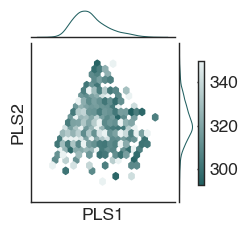

In [111]:


color = palette[0] if condition == 'WT' else palette[2]
palette_cmap = sns.light_palette(color, as_cmap=True)

embedding = pls_embedding.T# embedding_wt if condition == 'WT' else embedding_tm6

g = sns.jointplot(x=embedding[0], y=embedding[1], height=2.5, kind='kde', color=color)
io_func.scale_rcparams(g.fig, scalingf=0.5)
g.ax_joint.cla()
sc = g.ax_joint.hexbin(embedding[0], embedding[1], C=obj_vals, cmap=palette_cmap.reversed(), gridsize=20,vmax=350)#,vmax=2000)
cbar = plt.colorbar(sc, ax=g.ax_marg_y, fraction=0.25, pad=0.2)
g.ax_joint.set_yticks([])
g.ax_joint.set_xticks([])
g.ax_joint.set_xlabel(f'PLS1')
g.ax_joint.set_ylabel(f'PLS2')

# plt.savefig(f'{config.PLOTS_FOLDER}/fig5c_{condition}_normPLShex_2D.png',dpi=300,bbox_inches='tight')
# plt.savefig(f'{config.PLOTS_FOLDER}fig5c_{condition}_normPLShex_2D.svg',dpi=300,bbox_inches='tight')
